# Multilayer Perceptron (MLP)

- An MLP stacks layers of neurons: **input → hidden layer(s) → output**.
- It is trained with gradient descent; **backpropagation** is just the chain rule to get the gradients.

In [116]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Moons Dataset

In [117]:
## 500 points in two half moons; noise makes them overlap a little
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

## X: one row per point, two features (x1, x2)
print(X.shape)

## y: one label per point, 0 or 1
print(y.shape)

## balanced classes: 250 points each
print(np.unique(y, return_counts=True))

(500, 2)
(500,)
(array([0, 1]), array([250, 250]))


In [118]:
X[0:5]

array([[ 0.83085779, -0.33434228],
       [ 0.99170955,  0.87899966],
       [ 1.1072453 , -0.47034376],
       [-0.14089918,  1.03314844],
       [ 0.40559217,  1.32852876]])

In [119]:
y[0:5]

array([1, 0, 1, 0, 0])

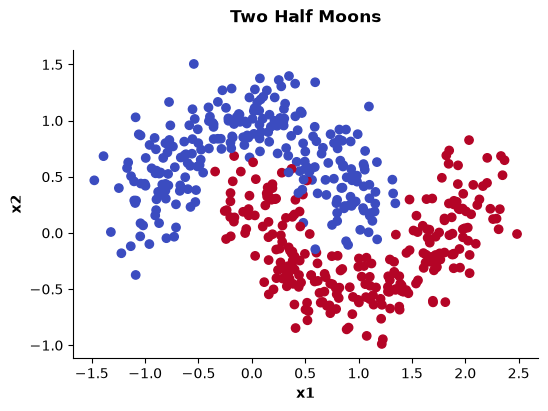

In [120]:
## two half moons, colored by class
fig, ax = plt.subplots(figsize=(6, 4))

scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm')

ax.set_xlabel('x1', weight='bold')
ax.set_ylabel('x2', weight='bold')
ax.set_title('Two Half Moons', weight='bold', pad=20)

ax.spines[['top', 'right']].set_visible(False)

plt.show()

# Train and Test Split

- Split 80% train / 20% test, keeping the class proportions.
- Architecture: **2 → 4 (sigmoid) → 1 (sigmoid)**, trained with full-batch gradient descent.

In [121]:
## 80% train / 20% test: stratify keeps 50/50 classes in both parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train.shape, X_test.shape

((400, 2), (100, 2))

In [122]:
## hyperparameters
hidden = 4
lr = 2.0
epochs = 5000

## NumPy from scratch

- Implement it yourself with the formulas above.
- Use matrix operations (`@`) for the whole batch: the only `for` loop is over the epochs.

In [123]:
## activation function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

## loss for regression
def mean_squared_error(y, y_hat):
    return np.mean((y - y_hat) ** 2)

## loss for binary classification (the one we use)
def binary_cross_entropy(y, y_hat):
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

In [124]:
## initial weights and biases
## W1: (2, hidden), b1: (hidden,) -> input to hidden
## W2: (hidden, 1), b2: (1,)      -> hidden to output
## random weights (fixed seed), biases at zero

### Train

In [125]:
## loop for training
## labels as a column (n, 1) to match y_hat: y_train.reshape(-1, 1)

## forward: Z1, A1, Z2, y_hat

## loss: save it every epoch to plot it later

## backward: dZ2, dW2, db2, dZ1, dW1, db1

## update: W = W - lr * dW, b = b - lr * db

### Test

- Only the forward pass with the trained weights; the predicted class is $1$ if $\hat{y} > 0.5$, else $0$.

In [126]:
## predict: forward pass on X_test with the trained weights

## class 1 if y_hat > 0.5, else 0

## accuracy: fraction of correct predictions

## scikit-learn

In [127]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

### Train

In [128]:
## hyperparameters
hidden = 4
lr = 2.0
epochs = 5000

In [129]:
## model setup: these are hyperparameters (we choose them)
## the parameters (weights and biases) are learned by fit
mlp = MLPClassifier(
    hidden_layer_sizes=(hidden,),
    activation='logistic',
    solver='sgd',
    learning_rate_init=lr,
    max_iter=epochs,
    random_state=42
)

mlp

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(4,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'logistic'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",2.0
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [130]:
## with binary labels, scikit-learn uses the binary cross-entropy loss
mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(4,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'logistic'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",2.0
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


### Test

In [131]:
## predict the class of each test point
y_pred = mlp.predict(X_test)

In [132]:
## accuracy: fraction of correct predictions
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')

Accuracy: 0.9800


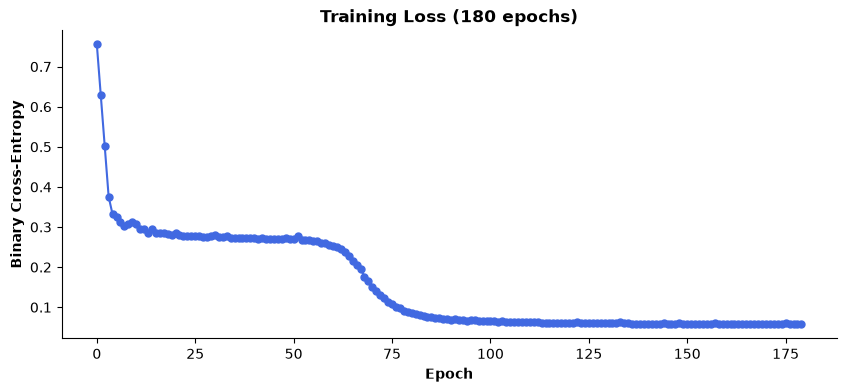

In [133]:
## training loss per epoch
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(mlp.loss_curve_, color='royalblue', marker='o', markersize=5)

ax.set_xlabel('Epoch', weight='bold')
ax.set_ylabel('Binary Cross-Entropy', weight='bold')
ax.set_title(f'Training Loss ({mlp.n_iter_} epochs)', weight='bold')

ax.spines[['top', 'right']].set_visible(False)

plt.show()